In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import h5py as h5
import os

In [2]:
# get present working directory
cwd = os.getcwd()
cwd

'/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/analyse_input_features'

In [3]:
data_dir = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set"

In [4]:
# load train.h5 file
train_file_path = os.path.join(data_dir, "train.h5")
train_file = h5.File(train_file_path, "r")
with h5.File(train_file_path, "r") as train_file:
    # List all groups
    print("Keys: %s" % train_file.keys())

Keys: <KeysViewHDF5 ['feature_names', 'index_ptr', 'stay_ids', 'trajectories']>


In [5]:
# load feature_names, index_ptr, stay_ids and trajectories
with h5.File(train_file_path, "r") as train_file:
    feature_names = train_file["feature_names"][:]
    index_ptr = train_file["index_ptr"][:]
    stay_ids = train_file["stay_ids"][:]
    trajectories = train_file["trajectories"][:]

In [6]:
# print features names, stored as bytes, so decode to string
feature_names = [name.decode("utf-8") for name in feature_names]
for name in feature_names:
    print(name)

airway_type
airway_type_mask
airway_type_delta
breath_sequence
breath_sequence_mask
breath_sequence_delta
control_variable
control_variable_mask
control_variable_delta
expiratory_pressure
expiratory_pressure_mask
expiratory_pressure_delta
fio2
fio2_mask
fio2_delta
inspiratory_time
inspiratory_time_mask
inspiratory_time_delta
mean_airway_pressure
mean_airway_pressure_mask
mean_airway_pressure_delta
mode_of_ventilation
mode_of_ventilation_mask
mode_of_ventilation_delta
nitric_oxide
nitric_oxide_mask
nitric_oxide_delta
oxygen_flow
oxygen_flow_mask
oxygen_flow_delta
peep
peep_mask
peep_delta
pip
pip_mask
pip_delta
weight_kg
ecls_support_type
on_ecls
furosemide
hydralazine
labetalol
nitroglycerin
nitroprusside
intake
output
alt
alt_mask
alt_delta
calcium
calcium_mask
calcium_delta
chloride
chloride_mask
chloride_delta
creatinine
creatinine_mask
creatinine_delta
crp
crp_mask
crp_delta
hematocrit
hematocrit_mask
hematocrit_delta
hemoglobin
hemoglobin_mask
hemoglobin_delta
neutrophil_count
neu

In [7]:
n_features = len(feature_names)
print(f"Number of features: {n_features}")

Number of features: 155


In [8]:
print("trajectories.shape):", trajectories.shape)


trajectories.shape): (5694306, 155)


In [9]:
# find intake feature index
intake_feature_index = feature_names.index("intake")
print(f"Index of 'intake' feature: {intake_feature_index}")

Index of 'intake' feature: 44


In [10]:
# find vis feature index
vis_feature_index = feature_names.index("vis")
print(f"Index of 'vis' feature: {vis_feature_index}")

Index of 'vis' feature: 146


In [11]:
intake = trajectories[:, intake_feature_index]
intake

array([ 0.,  0.,  3., ...,  0.,  0., 30.], dtype=float32)

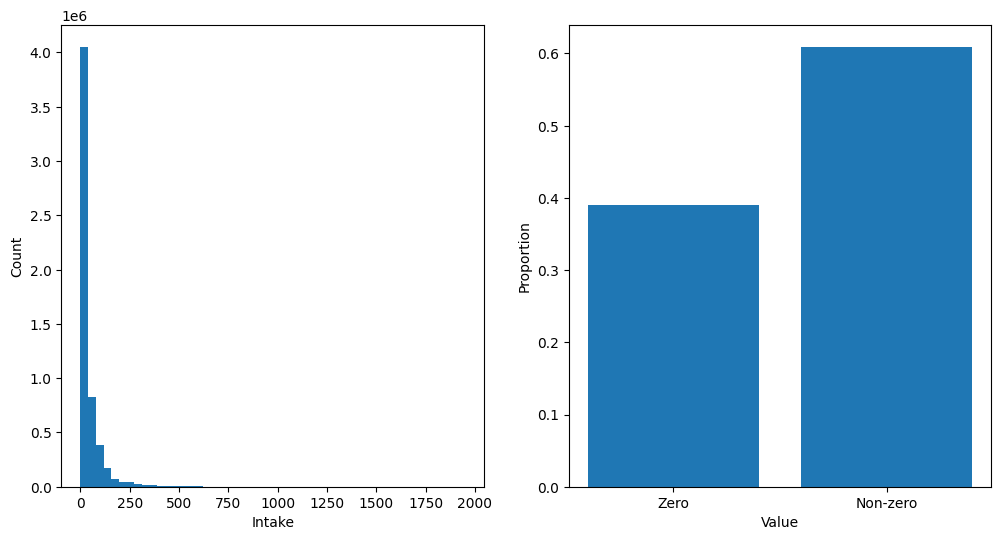

In [12]:
# plot full distribution of intake values is subplot on left
plt.subplot(1, 2, 1)
plt.hist(intake, bins=50)
plt.xlabel("Intake")
plt.ylabel("Count")

# plot a histogram of number of zero and non-zero values is two bars on the right subplot
total_count = len(intake)
n_zeros = np.sum(intake == 0)
n_non_zeros = np.sum(intake != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count

plt.subplot(1, 2, 2)
plt.bar(["Zero", "Non-zero"], [proportion_zeros, proportion_non_zeros])
plt.ylabel("Proportion") 
plt.xlabel("Value")

# make the figure wider
plt.gcf().set_size_inches(12, 6)

Text(0.5, 1.0, 'Distribution of non-zero intake values')

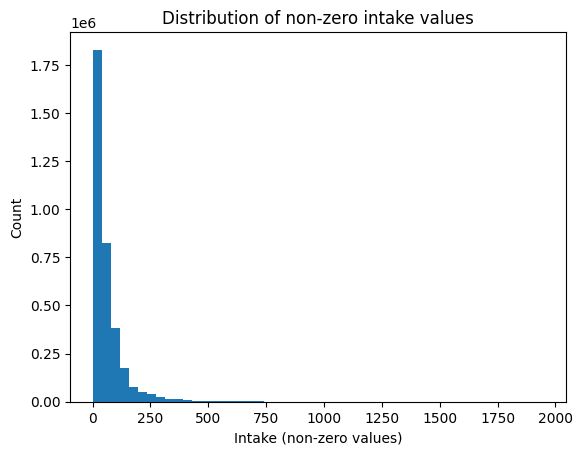

In [13]:

# plot the distribution of intake values for non-zero values only
non_zero_intake = intake[intake != 0]
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values")


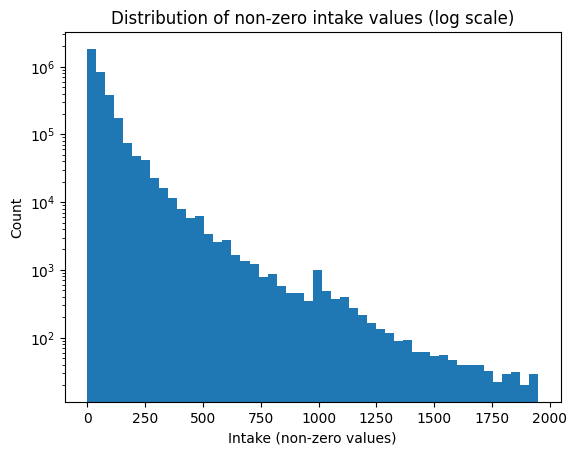

In [14]:
# plot the distribution of intake values for non-zero values only on log scale
plt.figure()
plt.hist(non_zero_intake, bins=50)
plt.xlabel("Intake (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero intake values (log scale)")
plt.yscale("log")

In [15]:
# print mean, median, std, min, max of intake values for non-zero values only
mean_intake = np.mean(non_zero_intake)
median_intake = np.median(non_zero_intake)
std_intake = np.std(non_zero_intake)
min_intake = np.min(non_zero_intake)
max_intake = np.max(non_zero_intake)
print(f"Mean of non-zero intake values: {mean_intake}")
print(f"Median of non-zero intake values: {median_intake}")
print(f"Standard deviation of non-zero intake values: {std_intake}")
print(f"Minimum of non-zero intake values: {min_intake}")   
print(f"Maximum of non-zero intake values: {max_intake}")   

Mean of non-zero intake values: 60.17668151855469
Median of non-zero intake values: 35.0
Standard deviation of non-zero intake values: 87.2989273071289
Minimum of non-zero intake values: 0.0010000000474974513
Maximum of non-zero intake values: 1948.550048828125


# Data processed for sepsis RL
'/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set/train_dynamic_deephit_dataset.h5' - think this is prenormalized
file has 2,488,216 rows
this gets reduced to 715,424 rows by sepsis cohort restriction

self.dynamic_deephit_predictions['model_outputs'].shape
(2488216, 512)
this gets reduced to 715,424 rows by sepsis cohort restriction

In [4]:
# load train_dynamic_deephit_dataset.h5 file
train_dynamic_deephit_dataset_file_path = os.path.join(data_dir, "train_dynamic_deephit_dataset.h5")
train_dynamic_deephit_dataset_file = h5.File(train_dynamic_deephit_dataset_file_path, "r")
with h5.File(train_dynamic_deephit_dataset_file_path, "r") as train_dynamic_deephit_dataset_file:
    # List all groups
    print("Keys: %s" % train_dynamic_deephit_dataset_file.keys())
    feature_names = train_dynamic_deephit_dataset_file["feature_names"][:]
    trajectories = train_dynamic_deephit_dataset_file["trajectories"][:]
    index_ptr = train_dynamic_deephit_dataset_file["index_ptr"][:]
    stay_ids = train_dynamic_deephit_dataset_file["stay_ids"][:]

Keys: <KeysViewHDF5 ['carry_forward_ind', 'event', 'feature_dim', 'feature_names', 'index_ptr', 'physiological_feature_ind', 'physiological_feature_type', 'response_zero_ind', 'stay_ids', 'time_to_event', 'time_to_event_raw', 'trajectories']>


In [5]:
dynamic_deephit_dir = '/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/final_model'
# find folder inside dynamic_deephit_dir
final_model_dir = [f for f in os.listdir(dynamic_deephit_dir) if os.path.isdir(os.path.join(dynamic_deephit_dir, f))][0]
final_model_dir_path = os.path.join(dynamic_deephit_dir, final_model_dir)

predictions_file_path = os.path.join(final_model_dir_path, "train_set_predictions.h5")
with h5.File(predictions_file_path, "r") as predictions_file:
    # List all groups
    print("Keys: %s" % predictions_file.keys())
    health_score = predictions_file["health_score"][:]
    index_ptr2 = predictions_file["index_ptr"][:]

Keys: <KeysViewHDF5 ['carry_forward_ind', 'compressed_latents', 'entropy', 'event', 'feature_dim', 'feature_names', 'health_score', 'index_ptr', 'model_outputs', 'physiological_feature_ind', 'physiological_feature_type', 'predictions', 'response_zero_ind', 'stay_ids']>


In [6]:
# check that index_ptr and index_ptr2 are the same
if np.array_equal(index_ptr, index_ptr2):
    print("index_ptr and index_ptr2 are the same")
else:
    print("index_ptr and index_ptr2 are NOT the same")

index_ptr and index_ptr2 are the same


In [7]:
# restrict to sepsis cohort
sepsis_cohort_path = "/home/jake/Documents/AI_Clinician/choc_data/cohorts/sepsis/stay_ids.csv"

# load sepsis cohort stay_ids
sepsis_stay_ids = pd.read_csv(sepsis_cohort_path)
sepsis_stay_ids

,stay_id
0,1163732912
1,1163738773
2,1163740044
3,1163744439
4,1163745160
...,...
5178,1189395190
5179,1189395314
5180,1189418957
5181,1189420203


In [8]:
# Create boolean mask for stays to keep
mask = np.isin(stay_ids, list(sepsis_stay_ids["stay_id"]))
indices_to_keep = np.where(mask)[0]

if index_ptr[-1] != trajectories.shape[0]:
    print("Inconsistent indexing detected, aborting filtering")
    print(f"Shape of unfiltered trajectories: {trajectories.shape}")
    print(f"Shape of unfiltered health_score: {health_score.shape}")
else:
    print("Indexing is consistent, proceeding with filtering")
    traj_mask = np.zeros(trajectories.shape[0], dtype=bool)
    for idx in indices_to_keep:
        start_idx = index_ptr[idx]
        end_idx = index_ptr[idx + 1]
        traj_mask[start_idx:end_idx] = True

    trajectories = trajectories[traj_mask]
    trajectories.shape
    print(f"Shape of trajectories after filtering for sepsis cohort: {trajectories.shape}")

    health_score = health_score[traj_mask]
    health_score.shape
    print(f"Shape of health_score after filtering for sepsis cohort: {health_score.shape}")

Indexing is consistent, proceeding with filtering
Shape of trajectories after filtering for sepsis cohort: (715424, 155)
Shape of health_score after filtering for sepsis cohort: (715424,)


## Intake

In [9]:
# get intake and vis feature indices from feature_names array
feature_names_str = np.asarray(feature_names).astype(str)

intake_matches = np.where(feature_names_str == "intake")[0]
vis_matches = np.where(feature_names_str == "vis")[0]
intake_feature_index = int(intake_matches[0])
vis_feature_index = int(vis_matches[0])

In [10]:
# get features from trajectories
intake = trajectories[:, intake_feature_index]
vis = trajectories[:, vis_feature_index]

In [11]:
# print n_rows
print(f"Number of rows: {len(intake)}")

Number of rows: 715424


In [12]:
# get mean, median, std, min, max of intake and vis features
mean_intake = np.mean(intake)
median_intake = np.median(intake)
std_intake = np.std(intake)
min_intake = np.min(intake)
max_intake = np.max(intake)

print(f"Mean of intake values: {mean_intake}")
print(f"Median of intake values: {median_intake}")
print(f"Standard deviation of intake values: {std_intake}")
print(f"Minimum of intake values: {min_intake}")
print(f"Maximum of intake values: {max_intake}")

Mean of intake values: 0.40887734293937683
Median of intake values: 0.47668302059173584
Standard deviation of intake values: 0.23940719664096832
Minimum of intake values: 0.0
Maximum of intake values: 1.0


In [13]:
# get mean, median, std, min, max of non-zero intake values
non_zero_intake = intake[intake != 0]
mean_non_zero_intake = np.mean(non_zero_intake)
median_non_zero_intake = np.median(non_zero_intake)
std_non_zero_intake = np.std(non_zero_intake)
min_non_zero_intake = np.min(non_zero_intake)
max_non_zero_intake = np.max(non_zero_intake)
print(f"Mean of non-zero intake values: {mean_non_zero_intake}")
print(f"Median of non-zero intake values: {median_non_zero_intake}")
print(f"Standard deviation of non-zero intake values: {std_non_zero_intake}")
print(f"Minimum of non-zero intake values: {min_non_zero_intake}")
print(f"Maximum of non-zero intake values: {max_non_zero_intake}")

Mean of non-zero intake values: 0.4943188428878784
Median of non-zero intake values: 0.5196921229362488
Standard deviation of non-zero intake values: 0.16449160873889923
Minimum of non-zero intake values: 0.0001319456350756809
Maximum of non-zero intake values: 1.0


Proportion of zero intake values: 0.17284715078051616
Proportion of non-zero intake values: 0.8271528492194838


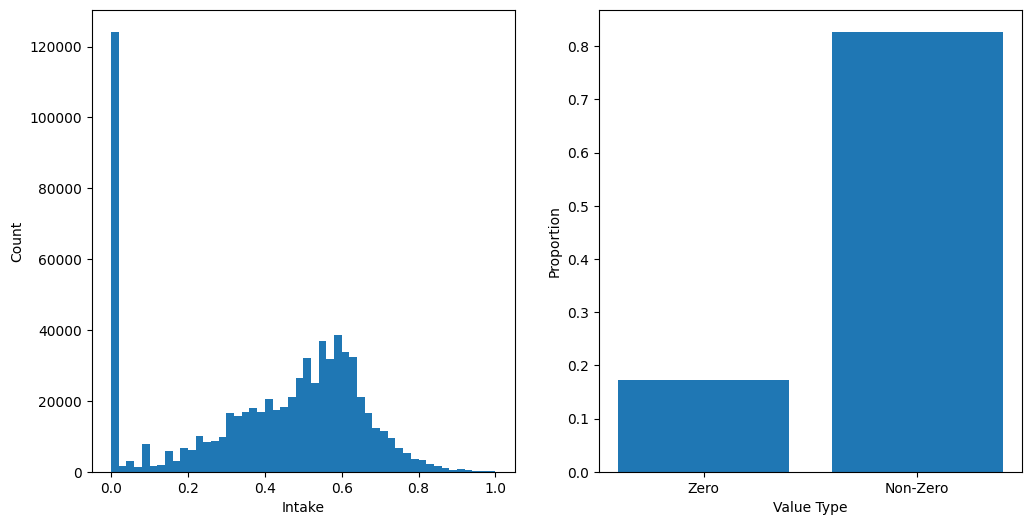

In [14]:
# plot distribution of intake values on left subplot, and proportion of zero and non-zero values on right subplot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(intake, bins=50)
plt.xlabel("Intake")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
total_count = len(intake)
n_zeros = np.sum(intake == 0)
n_non_zeros = np.sum(intake != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count
plt.bar([0, 1], [proportion_zeros, proportion_non_zeros], tick_label=["Zero", "Non-Zero"])
plt.xlabel("Value Type")
plt.ylabel("Proportion")   

print(f"Proportion of zero intake values: {proportion_zeros}")
print(f"Proportion of non-zero intake values: {proportion_non_zeros}")

## VIS

In [15]:
# get mean, median, std, min, max of vis feature
mean_vis = np.mean(vis)
median_vis = np.median(vis)
std_vis = np.std(vis)   
min_vis = np.min(vis)
max_vis = np.max(vis)

print(f"Mean of vis values: {mean_vis}")
print(f"Median of vis values: {median_vis}")
print(f"Standard deviation of vis values: {std_vis}")
print(f"Minimum of vis values: {min_vis}")
print(f"Maximum of vis values: {max_vis}")

Mean of vis values: 0.02021082490682602
Median of vis values: 0.0
Standard deviation of vis values: 0.0763692855834961
Minimum of vis values: 0.0
Maximum of vis values: 1.0


In [16]:
# get mean, median, std, min, max of non-zero vis values
non_zero_vis = vis[vis != 0]
mean_non_zero_vis = np.mean(non_zero_vis)
median_non_zero_vis = np.median(non_zero_vis)
std_non_zero_vis = np.std(non_zero_vis)
min_non_zero_vis = np.min(non_zero_vis)
max_non_zero_vis = np.max(non_zero_vis)
print(f"Mean of non-zero vis values: {mean_non_zero_vis}")
print(f"Median of non-zero vis values: {median_non_zero_vis}")
print(f"Standard deviation of non-zero vis values: {std_non_zero_vis}")
print(f"Minimum of non-zero vis values: {min_non_zero_vis}")
print(f"Maximum of non-zero vis values: {max_non_zero_vis}")

Mean of non-zero vis values: 0.26203885674476624
Median of non-zero vis values: 0.22199366986751556
Standard deviation of non-zero vis values: 0.11067347973585129
Minimum of non-zero vis values: 0.006044956389814615
Maximum of non-zero vis values: 1.0


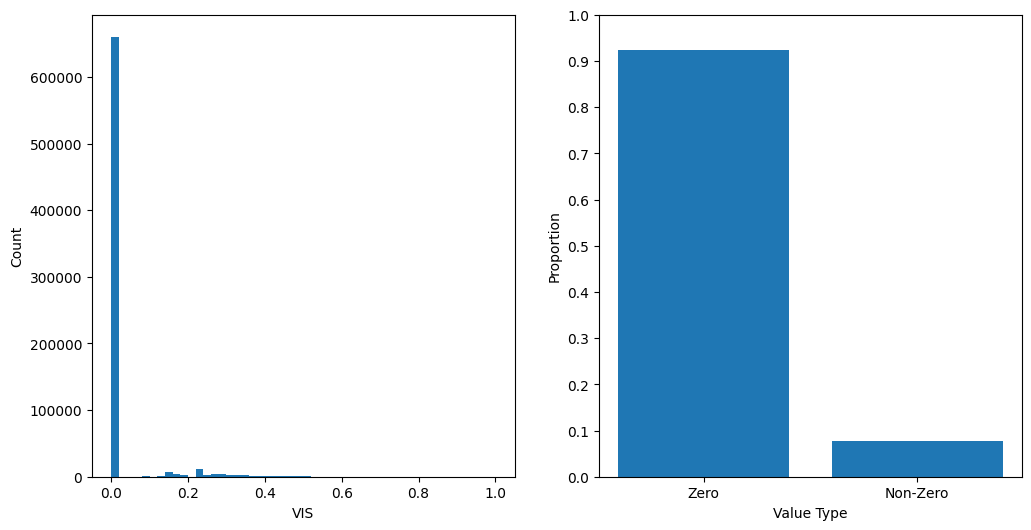

Proportion of zero doses for vis: 0.9228709129131816
Proportion of non-zero doses for vis: 0.07712908708681844


In [17]:
# plot distribution of vis values on left subplot, and proportion of zero and non-zero values on right subplot
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.hist(vis, bins=50)
plt.xlabel("VIS")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
total_count = len(vis)
n_zeros = np.sum(vis == 0)
n_non_zeros = np.sum(vis != 0)
proportion_zeros = n_zeros / total_count
proportion_non_zeros = n_non_zeros / total_count
plt.bar([0, 1], [proportion_zeros, proportion_non_zeros], tick_label=["Zero", "Non-Zero"])
plt.xlabel("Value Type")
plt.ylabel("Proportion")
# place y-ticks every 0.1
plt.yticks(np.arange(0, 1.1, 0.1))
plt.show()

print(f"Proportion of zero doses for vis: {proportion_zeros}")
print(f"Proportion of non-zero doses for vis: {proportion_non_zeros}")

Text(0.5, 1.0, 'Distribution of non-zero VIS values')

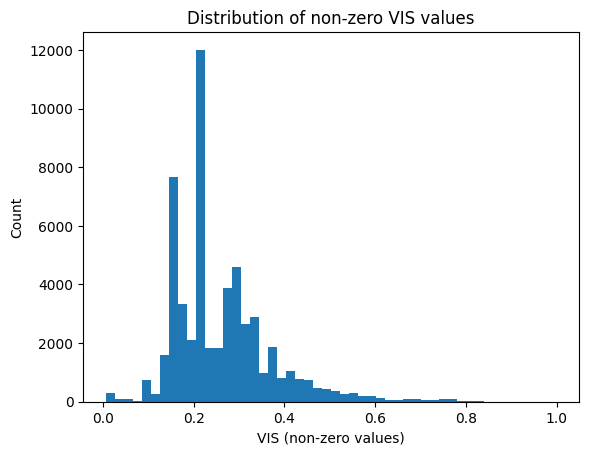

In [18]:
# plot just non-zero vis values as histogram
plt.figure()
plt.hist(non_zero_vis, bins=50)
plt.xlabel("VIS (non-zero values)")
plt.ylabel("Count")
plt.title("Distribution of non-zero VIS values")


# intake and vis

In [19]:
# get the rate of zero values for both simultaneously and plot as a bar chart
n_both_zero = np.sum((intake == 0) & (vis == 0))
n_intake_zero_vis_non_zero = np.sum((intake == 0) & (vis != 0))
n_intake_non_zero_vis_zero = np.sum((intake != 0) & (vis == 0))
n_intake_non_zero_vis_non_zero = np.sum((intake != 0) & (vis != 0))

total_count = len(intake)
proportion_both_zero = n_both_zero / total_count
proportion_intake_zero_vis_non_zero = n_intake_zero_vis_non_zero / total_count
proportion_intake_non_zero_vis_zero = n_intake_non_zero_vis_zero / total_count
proportion_intake_non_zero_vis_non_zero = n_intake_non_zero_vis_non_zero / total_count

print(f"Proportion of both intake and vis zero: {proportion_both_zero}")
print(f"Proportion of intake zero and vis non-zero: {proportion_intake_zero_vis_non_zero}")
print(f"Proportion of intake non-zero and vis zero: {proportion_intake_non_zero_vis_zero}")
print(f"Proportion of both intake and vis non-zero: {proportion_intake_non_zero_vis_non_zero}")


Proportion of both intake and vis zero: 0.17264028044907634
Proportion of intake zero and vis non-zero: 0.00020687033143981752
Proportion of intake non-zero and vis zero: 0.7502306324641052
Proportion of both intake and vis non-zero: 0.07692221675537862


# Health score

In [20]:
# print health score mean, median, std, min, max
mean_health_score = np.mean(health_score)
median_health_score = np.median(health_score)
std_health_score = np.std(health_score)
min_health_score = np.min(health_score)
max_health_score = np.max(health_score)
print(f"Mean of health score values: {mean_health_score}")
print(f"Median of health score values: {median_health_score}")
print(f"Standard deviation of health score values: {std_health_score}")
print(f"Minimum of health score values: {min_health_score}")
print(f"Maximum of health score values: {max_health_score}")

Mean of health score values: 77.80574798583984
Median of health score values: 81.04046630859375
Standard deviation of health score values: 15.381834983825684
Minimum of health score values: 5.810382843017578
Maximum of health score values: 98.25191497802734


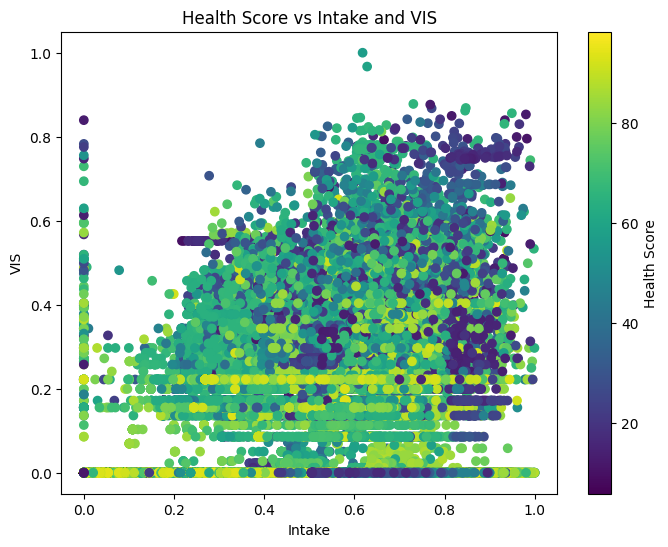

In [21]:
# plot a linear regression of health score vs intake and vis values, with intake on x-axis 
# and vis on y-axis, and health score as color
plt.figure(figsize=(8, 6))
plt.scatter(intake, vis, c=health_score, cmap='viridis')
plt.xlabel('Intake')
plt.ylabel('VIS')
plt.title('Health Score vs Intake and VIS')
plt.colorbar(label='Health Score')
plt.show()

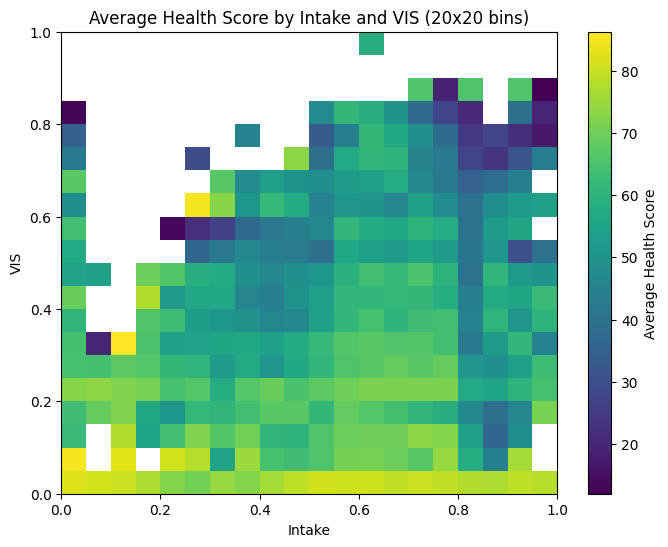

In [29]:
# plot average health score as a 20x20 heatmap over intake (x) and vis (y),
# with unoccupied bins shown in white instead of the colormap
n_bins = 20

joint_counts, fluid_edges, vaso_edges = np.histogram2d(intake, vis, bins=n_bins)
health_sums, _, _ = np.histogram2d(intake, vis, bins=[fluid_edges, vaso_edges], weights=health_score)

with np.errstate(invalid="ignore", divide="ignore"):
    avg_health = health_sums / joint_counts
avg_health = np.ma.masked_where(joint_counts == 0, avg_health)

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="white")

plt.figure(figsize=(8, 6))
im = plt.pcolormesh(fluid_edges, vaso_edges, avg_health.T, cmap=cmap, shading="auto")
plt.xlabel("Intake")
plt.ylabel("VIS")
plt.title("Average Health Score by Intake and VIS (20x20 bins)")
plt.colorbar(im, label="Average Health Score")
plt.show()

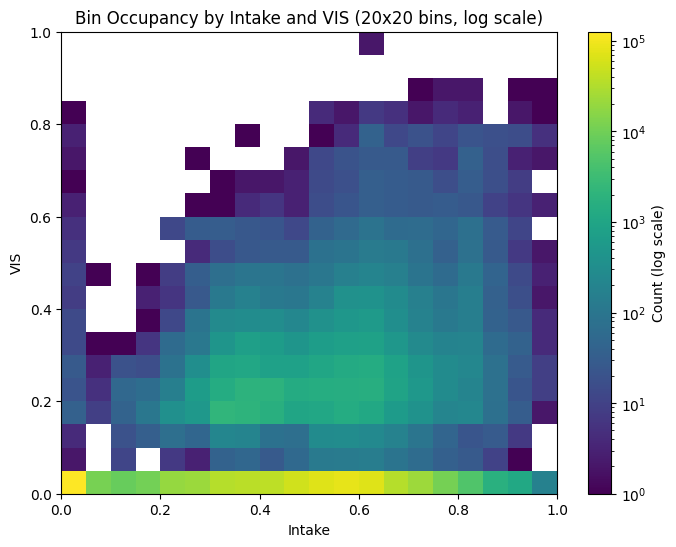

In [30]:
# plot the same 20x20 heatmap, but heat is bin occupancy (count) instead of average health score,
# with unoccupied bins shown in white instead of the colormap, and counts on a log scale
from matplotlib.colors import LogNorm

counts_masked = np.ma.masked_where(joint_counts == 0, joint_counts)

cmap_counts = plt.get_cmap("viridis").copy()
cmap_counts.set_bad(color="white")

plt.figure(figsize=(8, 6))
im = plt.pcolormesh(
    fluid_edges, vaso_edges, counts_masked.T, cmap=cmap_counts,
    norm=LogNorm(vmin=1, vmax=counts_masked.max()), shading="auto",
)
plt.xlabel("Intake")
plt.ylabel("VIS")
plt.title("Bin Occupancy by Intake and VIS (20x20 bins, log scale)")
plt.colorbar(im, label="Count (log scale)")
plt.show()

In [31]:
def build_zero_occupancy_action_pool(fluid_bin_edges, vaso_bin_edges, joint_counts, min_count=1):
    """
    Identifies action-space bins with near-zero occupancy in the dataset,
    and returns their bounds so we can sample actions uniformly within
    each unsupported bin. joint_counts: (n_fluid_bins, n_vaso_bins) array.
    """
    zero_bins = []
    for i in range(joint_counts.shape[0]):
        for j in range(joint_counts.shape[1]):
            if joint_counts[i, j] < min_count:
                zero_bins.append((
                    fluid_bin_edges[i], fluid_bin_edges[i + 1],
                    vaso_bin_edges[j], vaso_bin_edges[j + 1],
                ))
    return zero_bins  # list of (f_lo, f_hi, v_lo, v_hi)

In [36]:
# once, at trainer init or setup
zero_bins = build_zero_occupancy_action_pool(fluid_edges, vaso_edges, joint_counts, min_count=1)
zero_bins

[(0.0, 0.05, 0.8500000000000001, 0.9),
 (0.0, 0.05, 0.9, 0.9500000000000001),
 (0.0, 0.05, 0.9500000000000001, 1.0),
 (0.05, 0.1, 0.05, 0.1),
 (0.05, 0.1, 0.1, 0.15000000000000002),
 (0.05, 0.1, 0.35000000000000003, 0.4),
 (0.05, 0.1, 0.4, 0.45),
 (0.05, 0.1, 0.5, 0.55),
 (0.05, 0.1, 0.55, 0.6000000000000001),
 (0.05, 0.1, 0.6000000000000001, 0.65),
 (0.05, 0.1, 0.65, 0.7000000000000001),
 (0.05, 0.1, 0.7000000000000001, 0.75),
 (0.05, 0.1, 0.75, 0.8),
 (0.05, 0.1, 0.8, 0.8500000000000001),
 (0.05, 0.1, 0.8500000000000001, 0.9),
 (0.05, 0.1, 0.9, 0.9500000000000001),
 (0.05, 0.1, 0.9500000000000001, 1.0),
 (0.1, 0.15000000000000002, 0.35000000000000003, 0.4),
 (0.1, 0.15000000000000002, 0.4, 0.45),
 (0.1, 0.15000000000000002, 0.45, 0.5),
 (0.1, 0.15000000000000002, 0.5, 0.55),
 (0.1, 0.15000000000000002, 0.55, 0.6000000000000001),
 (0.1, 0.15000000000000002, 0.6000000000000001, 0.65),
 (0.1, 0.15000000000000002, 0.65, 0.7000000000000001),
 (0.1, 0.15000000000000002, 0.7000000000000001,